# Quick Clustering Workflow

This notebook demonstrates a quick clustering workflow used in detecting the different types of pockets in a nanoporouse material. It uses a collection of default parameters and may not work perfectly for all materials. But, it is a good starting point for tuning. The steps used in this workflow are:

- Compute the grid
- Compute the local maxima in the grid
- Compute region segmentation
- Apply periodic boundary conditions
- Detect connectivity and construct a pore graph
- Add some basic properties to the nodes of the pore graph
- Make figures with all the information

## Tips and Tricks #1

All the possible arguments to the function can be looked at using the `help` function.

```python
help(mgr.quick_cluster)
```


## Imports

In [1]:
# add path to mofography
import os,sys
path_to_mgr = os.path.abspath('C:/Users/arung/OneDrive - The University of Manchester/my_cloned_repos/22sep2024/mofography/')
# sys.path.append(path_to_mgr)
import mofography as mgr

from ase.io import read

path_to_cif = os.path.join(path_to_mgr, 'examples', 'TestCIFs', 'P1-IRMOF-1.cif')


## Read the CIF file

In [2]:
mat_atoms = read(path_to_cif)

# figures = mgr.quick_cluster(mat_atoms, return_these_vars=[figures])

c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\ase\io\cif.py:408: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(


## Run the quick cluster

Let's run the quick cluster with default params. By default, it returns only the figures. We can see later how to get other outputs from the workflow.

In [3]:
figures = mgr.quick_cluster(mat_atoms)


c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\mofography-0.0.0-py3.11.egg\mofography\compute.py:904: UserWarning: Some maxima excluded as they fell inside the mask_thickness
  warnings.warn("Some maxima excluded as they fell inside the mask_thickness")
comp. dist. for clustering: 100%|██████████| 28/28 [00:00<00:00, 1076.93it/s]


[0.34055939907688115, 0.34055939907688115, 0.07935527190748871, 0.34055939907688115, 0.07935527190748871, 0.07935527190748871, 0.427478177991364, 0.0, 0.294069921024694, 0.0, 0.294069921024694, 0.294069921024694, 0.17762491087859772, 0.294069921024694, 0.0, 0.294069921024694, 0.294069921024694, 0.17762491087859772, 0.294069921024694, 0.0, 0.0, 0.39212816421403385, 0.294069921024694, 0.294069921024694, 0.17762491087859772, 0.0, 0.39212816421403385, 0.39212816421403385]


c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\pyvista\core\pointset.py:1365: PyVistaDeprecationWarning:

The current behavior of `pv.PolyData.n_faces` has been deprecated.
                Use `pv.PolyData.n_cells` or `pv.PolyData.n_faces_strict` instead.
                See the documentation in '`pv.PolyData.n_faces` for more information.



No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate
No return objects specified, possible options to pass in list_return_strings are:
dict_keys(['ase_atoms', 'spacing', 'mask_thickness', 'h', 'compactness', 'zoom_ratio', 'wall_thickness', 'isoval', 'bins', 'block_size', 'a', 'b', 'c', 'density', 'js_threshold', 'distance_threshold', 'minimum_overlap_fraction', 'make_figures', 'renderer', 'sample_fraction', 'cscale', 'return_these_vars', 'np', 'inspect', 'covalent_radii', 'ase', 'make_supercell', 'da', 'zoom', 'regionprops', 'go', 'px', 'update_with_covalent_bonds', 'dgrid_from_atoms_cpu', 'regions_from_dgrid', 'apply_pbc', 'connections_from_regions_and_dgrid', 'rag_from_connections', 'add_pbc_to_rag', 'add_centroids_to_rag_with_pbc', 'add_psd_to_rag_with_pbc', 'clustering_grid_from_regions', 'add_clustering_to_ra

## The first figure

The first figure we are going to look at is quite loaded with information. It shows three isosurfaces (one on top of the other, so you have to toggle the top layers to see the bottom ones), the local maxima, the unit cell and the framework (atoms, bonds and aromatic rings). The three isosurfaces correspond to
- The raw region segmentation
- The region segmentation after applying periodic boundary conditions, where regions that are connected across the periodic boundary are merged to the same index
- The types of pockets, where all the pockets detected to be of the same type and shown in the same color. 

There is more information available in the figure if you hover over any of the surfaces or the framework atoms.

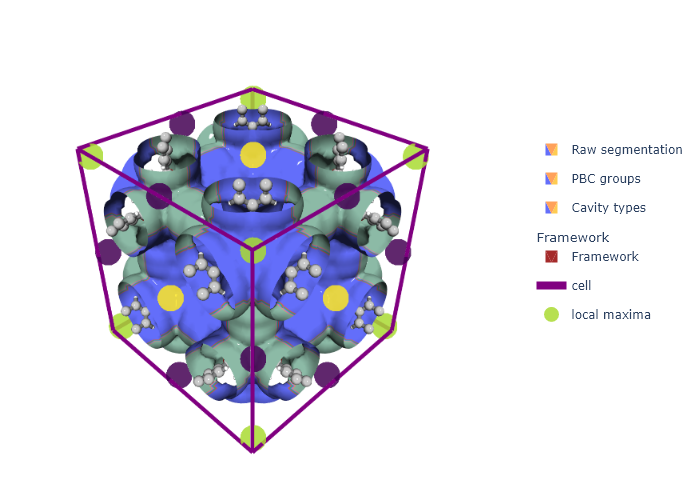

In [4]:
figures[0].show(renderer='png')
# figures[0].show()

Any of the plot traces can be recoverd using the data variable of the Plotly figure object. 
`fig.data`. For example, to just see the names of the traces use. Please refer to Plotly documentation for more informaton on the figure structures  https://plotly.com/python/figure-structure/

In [5]:
[d['name'] for d in figures[0].data]

['Raw segmentation',
 'PBC groups',
 'Cavity types',
 'Framework',
 'Aromatic rings',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'Aromatic highlights',
 'cell',
 'local maxima']

To set a different color scheme, say for the `Cavity types` mesh trace to `Pastel`, you can do that also post generation.

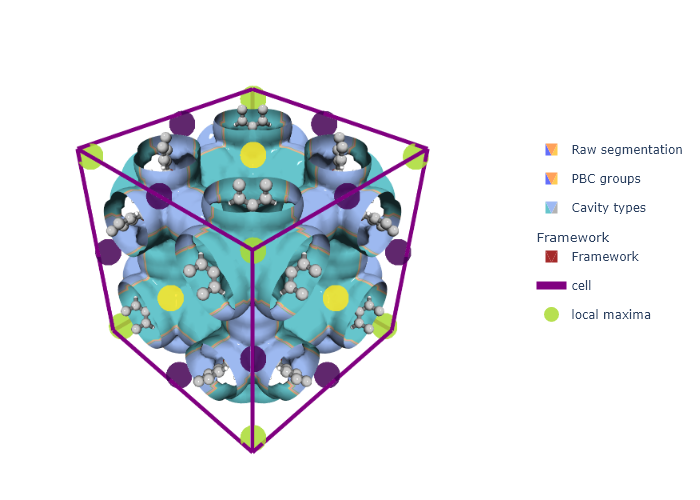

In [6]:
fig = figures[0]
import plotly.express as px 
fig.data[2]['colorscale'] = px.colors.qualitative.Pastel

fig.show(renderer='png')

## The second figure
 
The second figure returned simply contains the Cavity features that are used in clustering the pockets. One trace per PBC group. The traces are then colored by the cluster to which they belong to (shows on hover). This is quite useful for debugging and understanding the efficiency of our features in conjunction with the clustering algorithm.

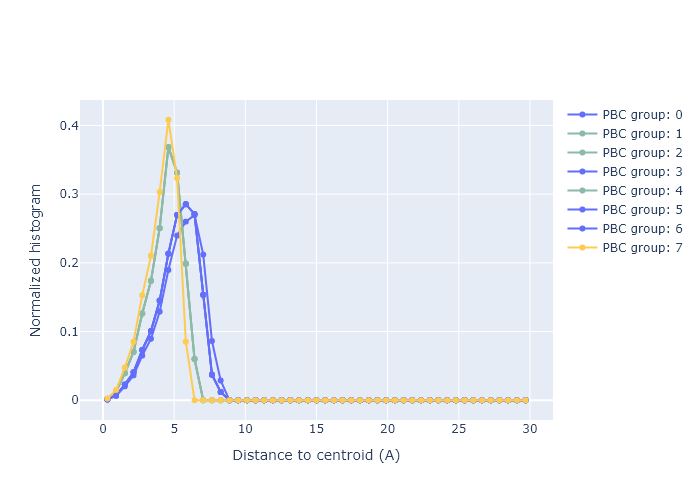

In [7]:
figures[1].show(renderer='png')

## Recovering additional outputs
We can grab additional variables with these names:
- grid: the dask grid of distances. To make it into a numpy array, use `grid.compute()`
- maxima: indices of the local maxima in the grid
- rag: region adjacency graph or the pore graph, which is a networkx graph


Let's exract the pore graph (region adjacency graph) and add that also to the first figure.

In [8]:
rag, figures = mgr.quick_cluster(mat_atoms, return_these_vars=['rag'])

c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\mofography-0.0.0-py3.11.egg\mofography\compute.py:904: UserWarning:

Some maxima excluded as they fell inside the mask_thickness

comp. dist. for clustering: 100%|██████████| 28/28 [00:00<00:00, 1119.97it/s]


[0.34055939907688115, 0.34055939907688115, 0.07935527190748871, 0.34055939907688115, 0.07935527190748871, 0.07935527190748871, 0.427478177991364, 0.0, 0.294069921024694, 0.0, 0.294069921024694, 0.294069921024694, 0.17762491087859772, 0.294069921024694, 0.0, 0.294069921024694, 0.294069921024694, 0.17762491087859772, 0.294069921024694, 0.0, 0.0, 0.39212816421403385, 0.294069921024694, 0.294069921024694, 0.17762491087859772, 0.0, 0.39212816421403385, 0.39212816421403385]
No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate
Some return objects specified, possible options to pass in list_return_strings are:


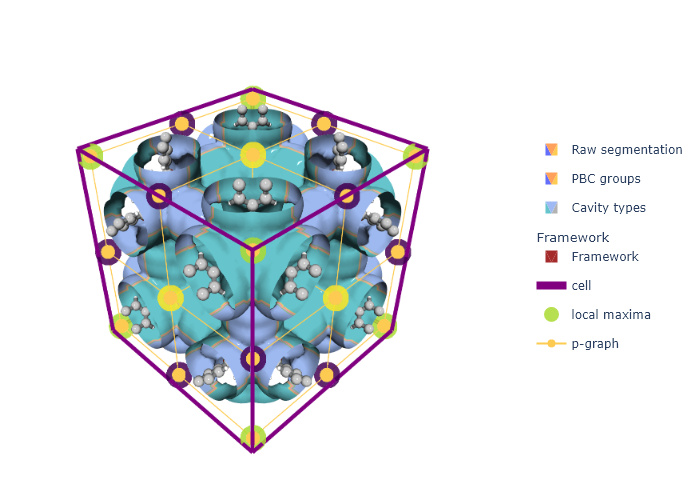

In [9]:
rag_trace = mgr.plot_rag(rag, name='p-graph')
fig.add_trace(rag_trace)
fig.show(renderer='png')

## Where to next

Now that you've seen the utility mofography by using it somewhat like a 'black box', you can start to dig deep into the key steps of this core workflow by going through the Basic Tutorials. You may also look at the Advanced Tutorials, if all you need is to apply mofography to a specific real-world problem similar to one detailed there.